# Module C, Week 4: Logistic Regression and Feature Scaling
### Integrated Capstone Project: Predicting Corporate Bankruptcy from Financial Ratios
**Astha Goel**

---

## Where this picks up

The capstone predicts corporate bankruptcy from published financial ratios, running an identical pipeline
separately on two datasets and comparing the *results* rather than merging them:

| | Poland | Taiwan |
|---|---|---|
| Observations | 43,405 firm-years (2000 to 2013) | 6,819 firms (1999 to 2009) |
| Features | 64 financial ratios | 95 financial ratios |
| Bankrupt | 2,091 (4.8%) | 220 (3.2%) |

**Module B** established that no single ratio predicts bankruptcy alone, that PCA does not compress these data, and
that a random forest nonetheless reaches ROC-AUC 0.9395 (Poland) and 0.9482 (Taiwan).

**Mod C Week 2** added regularization and turned up two things that drive this week's work:

1. Both datasets contain features ranging up to 10 billion. Trees ignore scale so this went unnoticed for an
   entire module; linear models collapsed to a test R² near -3 x 10^15 until I winsorized at 1%/99%.
2. Regularized logistic regression slightly beat the random forest in Taiwan (0.951 vs 0.948) but badly
   underperformed in Poland (0.778 vs 0.940). I hypothesised that **Poland's bankruptcy signal lives in
   interactions between ratios**, which a linear model structurally cannot represent.

## What Week 4 does

Week 2 used one scaler (`StandardScaler`) and one fix for outliers (winsorizing) without ever testing whether
either was the right choice. This week treats both as open questions, and then tests the interaction hypothesis
directly.

1. **Benchmark six scaling strategies** on raw, unwinsorized data (does the right scaler fix the outlier problem
   without clipping anything?)
2. **Interpret the logistic model properly** via odds ratios, which is the payoff for Taiwan where the linear
   model is competitive.
3. **Examine class weighting and probability calibration** a model can rank well and still output probabilities
   that are badly wrong.
4. **Tune the decision threshold against a cost function**, since Module B showed missed bankruptcies and false
   alarms are not equally expensive.
5. **Test the Week 2 interaction hypothesis** by adding pairwise interaction terms and seeing whether Poland's gap
   to the random forest closes.

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   QuantileTransformer, PowerTransformer,
                                   FunctionTransformer, PolynomialFeatures)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, confusion_matrix, brier_score_loss,
                             classification_report, precision_recall_curve)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

In [2]:
# ── TAIWAN ────────────────────────────────────────────────────────────────────
df_taiwan = pd.read_csv('Taiwan_data_capstone.csv')
df_taiwan.columns = df_taiwan.columns.str.strip()   # headers carry a leading space
df_taiwan['Bankrupt?'] = pd.to_numeric(df_taiwan['Bankrupt?'], errors='coerce').astype(int)

numeric_cols_taiwan = df_taiwan.select_dtypes(include='number').columns.tolist()
numeric_cols_taiwan = [c for c in numeric_cols_taiwan if c not in ['Bankrupt?']]
for col in numeric_cols_taiwan:
    df_taiwan[col] = df_taiwan[col].fillna(df_taiwan[col].median())

const_cols_taiwan = [c for c in numeric_cols_taiwan if df_taiwan[c].nunique() <= 1]
numeric_cols_taiwan = [c for c in numeric_cols_taiwan if c not in const_cols_taiwan]
print("Dropped constant Taiwan columns:", const_cols_taiwan)
print(f"Taiwan: {df_taiwan.shape}, {len(numeric_cols_taiwan)} usable features")
print(df_taiwan['Bankrupt?'].value_counts().to_dict())

Dropped constant Taiwan columns: ['Net Income Flag']
Taiwan: (6819, 96), 94 usable features
{0: 6599, 1: 220}


In [3]:
# ── POLAND ────────────────────────────────────────────────────────────────────
df_polish = pd.read_csv('Polish_dataset_capstone.csv')

column_names_64 = [
    'net_profit_to_total_assets', 'total_liabilities_to_total_assets',
    'working_capital_to_total_assets', 'current_assets_to_short_term_liabilities',
    'cash_to_operating_expenses', 'retained_earnings_to_total_assets',
    'EBIT_to_total_assets', 'book_value_of_equity_to_total_liabilities',
    'sales_to_total_assets', 'equity_to_total_assets',
    'gross_profit_to_short_term_liabilities', 'gross_profit_to_total_assets',
    'gross_profit_to_sales', 'gross_profit_to_total_assets_2',
    'working_capital_to_fixed_assets', 'receivables_to_total_assets',
    'liabilities_to_total_assets_duration', 'EBIT_to_total_assets_2',
    'sales_to_total_assets_2', 'working_capital_to_sales',
    'sales_to_inventories', 'net_profit_to_sales',
    'gross_profit_to_total_assets_3', 'current_liabilities_to_equity',
    'short_term_liabilities_to_equity', 'working_capital',
    'depreciation_to_total_assets', 'inventories_to_sales',
    'net_profit_to_inventories', 'total_liabilities_to_equity',
    'profit_on_sales_to_total_assets', 'total_liabilities_to_cash',
    'operating_expenses_to_short_term_liabilities', 'operating_expenses_to_total_liabilities',
    'profit_to_total_assets', 'net_profit_to_total_assets_2',
    'total_liabilities_to_operating_cash', 'total_liabilities_to_total_assets_rotation',
    'profit_to_long_term_liabilities', 'total_assets_to_total_liabilities',
    'short_term_liabilities_to_long_term_liabilities', 'short_term_liabilities_to_equity_2',
    'long_term_liabilities_to_equity', 'sales_to_short_term_liabilities',
    'inventory_to_receivables', 'receivables_to_sales',
    'net_profit_to_total_assets_3', 'total_costs_to_total_sales',
    'long_term_liabilities_to_total_assets', 'sales_to_equity',
    'sales_to_total_assets_3', 'liabilities_to_working_capital',
    'operating_cash_to_liabilities', 'operating_cash_to_total_liabilities',
    'operating_cash_to_sales', 'sales_to_receivables',
    'operating_expenses_to_sales', 'total_costs_to_total_assets',
    'profit_on_operating_activities', 'depreciation_to_profit',
    'total_liabilities_to_profit', 'profit_on_operating_activities_to_financial_expenses',
    'working_capital_to_liabilities', 'equity_to_fixed_assets'
]
rename_map = {f'A{i+1}': column_names_64[i] for i in range(64)}
df_polish = df_polish.rename(columns=rename_map)

# Force ratio columns numeric: if any arrive as strings, select_dtypes would skip them silently
for c in column_names_64:
    if c in df_polish.columns:
        df_polish[c] = pd.to_numeric(df_polish[c], errors='coerce')
df_polish['class'] = pd.to_numeric(df_polish['class'], errors='coerce').astype(int)

numeric_cols_polish = df_polish.select_dtypes(include='number').columns.tolist()
numeric_cols_polish = [c for c in numeric_cols_polish if c not in ['class', 'year', 'id']]
for col in numeric_cols_polish:
    df_polish[col] = df_polish[col].fillna(df_polish[col].median())

const_cols_polish = [c for c in numeric_cols_polish if df_polish[c].nunique() <= 1]
numeric_cols_polish = [c for c in numeric_cols_polish if c not in const_cols_polish]
print("Dropped constant Polish columns:", const_cols_polish)
print(f"Poland: {df_polish.shape}, {len(numeric_cols_polish)} usable features")
print(df_polish['class'].value_counts().to_dict())

Dropped constant Polish columns: []
Poland: (43405, 66), 64 usable features
{0: 41314, 1: 2091}


## 2. Why scaling matters for logistic regression

Logistic regression fits coefficients by gradient-based optimisation. When features live on wildly different
scales, the loss surface becomes a long narrow valley and the optimiser either takes a very long time to reach the
bottom or stops before it gets there. Regularization compounds the problem, since the penalty is applied to
coefficient magnitude without regard to the units those coefficients are expressed in.

Trees have neither issue, they split on rank order, so a feature measured in billions and the same feature
measured in units produce an identical tree. That difference is exactly why these datasets' scale problems stayed
invisible through all of Module B.

Here is the scale situation, as a reminder of what any scaler has to cope with.

In [4]:
def scale_report(df, cols, name, n=6):
    d = df[cols].describe().T[['min', '50%', 'max']]
    d['range'] = d['max'] - d['min']
    print(f"--- {name}: widest-ranging features ---")
    print(d.sort_values('range', ascending=False).head(n)
            .to_string(float_format=lambda x: f"{x:,.1f}"))
    print()

scale_report(df_taiwan, numeric_cols_taiwan, 'TAIWAN')
scale_report(df_polish, numeric_cols_polish, 'POLAND')

--- TAIWAN: widest-ranging features ---
                                 min             50%              max            range
Quick Asset Turnover Rate        0.0             0.0 10,000,000,000.0 10,000,000,000.0
Current Asset Turnover Rate      0.0             0.0 10,000,000,000.0 10,000,000,000.0
Cash Turnover Rate               0.0 1,080,000,000.0 10,000,000,000.0 10,000,000,000.0
Operating Expense Rate           0.0             0.0  9,990,000,000.0  9,990,000,000.0
Fixed Assets Turnover Frequency  0.0             0.0  9,990,000,000.0  9,990,000,000.0
Total Asset Growth Rate          0.0 6,400,000,000.0  9,990,000,000.0  9,990,000,000.0

--- POLAND: widest-ranging features ---
                                                               min   50%          max        range
long_term_liabilities_to_equity                         -115,870.0  99.4 30,393,000.0 30,508,870.0
profit_on_operating_activities_to_financial_expenses  -2,336,500.0  71.3 25,016,000.0 27,352,500.0
sales_to_shor

## 3. Scaler bake-off on raw, unwinsorized data

In Week 2 I reached for `StandardScaler` and fixed the outliers by winsorizing, without checking whether either
decision was optimal. This section tests six strategies on the **raw** data, no winsorizing at all, to see
whether the choice of scaler alone can handle the extreme values.

- **None**: a control, to show what scaling buys.
- **StandardScaler**: subtract mean, divide by standard deviation. The default, but both statistics are
  themselves distorted by extreme outliers.
- **MinMaxScaler**: squeeze into [0, 1]. Highly sensitive to the max, which here may be 10 billion.
- **RobustScaler**: subtract median, divide by interquartile range. Advertised as outlier-resistant.
- **QuantileTransformer**: map each feature to a normal distribution by *rank*. Magnitude is discarded entirely,
  so an outlier simply becomes "the largest value" rather than "ten billion".
- **PowerTransformer** (Yeo-Johnson): a learned power transform that reduces skew.

I also record the iteration count, since failure to converge is itself diagnostic.

In [5]:
def scaler_bakeoff(df, feats, target, name, max_iter=1000):
    X = df[feats].values
    y = df[target].values
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

    scalers = {
        'None (raw)':          FunctionTransformer(),
        'StandardScaler':      StandardScaler(),
        'MinMaxScaler':        MinMaxScaler(),
        'RobustScaler':        RobustScaler(),
        'QuantileTransformer': QuantileTransformer(output_distribution='normal',
                                                   random_state=RANDOM_STATE),
        'PowerTransformer':    PowerTransformer(method='yeo-johnson'),
    }

    rows = []
    for label, sc in scalers.items():
        pipe = make_pipeline(sc, LogisticRegression(
            C=1.0, class_weight='balanced', max_iter=max_iter))
        try:
            pipe.fit(Xtr, ytr)
            auc = roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1])
            n_it = int(np.max(pipe[-1].n_iter_))
            rows.append({'Scaler': label, 'Test ROC-AUC': auc,
                         'Iterations': n_it, 'Converged': n_it < max_iter})
        except Exception as e:
            rows.append({'Scaler': label, 'Test ROC-AUC': np.nan,
                         'Iterations': -1, 'Converged': False})

    res = pd.DataFrame(rows)
    print(f"\n=== {name}: logistic regression on RAW (unwinsorized) features ===")
    print(res.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    return res

bake_tw = scaler_bakeoff(df_taiwan, numeric_cols_taiwan, 'Bankrupt?', 'TAIWAN')
bake_pl = scaler_bakeoff(df_polish, numeric_cols_polish, 'class', 'POLAND')


=== TAIWAN: logistic regression on RAW (unwinsorized) features ===
             Scaler  Test ROC-AUC  Iterations  Converged
         None (raw)        0.6220         313       True
     StandardScaler        0.9171         116       True
       MinMaxScaler        0.9376          69       True
       RobustScaler        0.6083         967       True
QuantileTransformer        0.9398         192       True
   PowerTransformer        0.9181         133       True

=== POLAND: logistic regression on RAW (unwinsorized) features ===
             Scaler  Test ROC-AUC  Iterations  Converged
         None (raw)        0.6912        1000      False
     StandardScaler        0.7357         128       True
       MinMaxScaler        0.6033          18       True
       RobustScaler        0.7327        1000      False
QuantileTransformer        0.8146         144       True
   PowerTransformer        0.7740         193       True


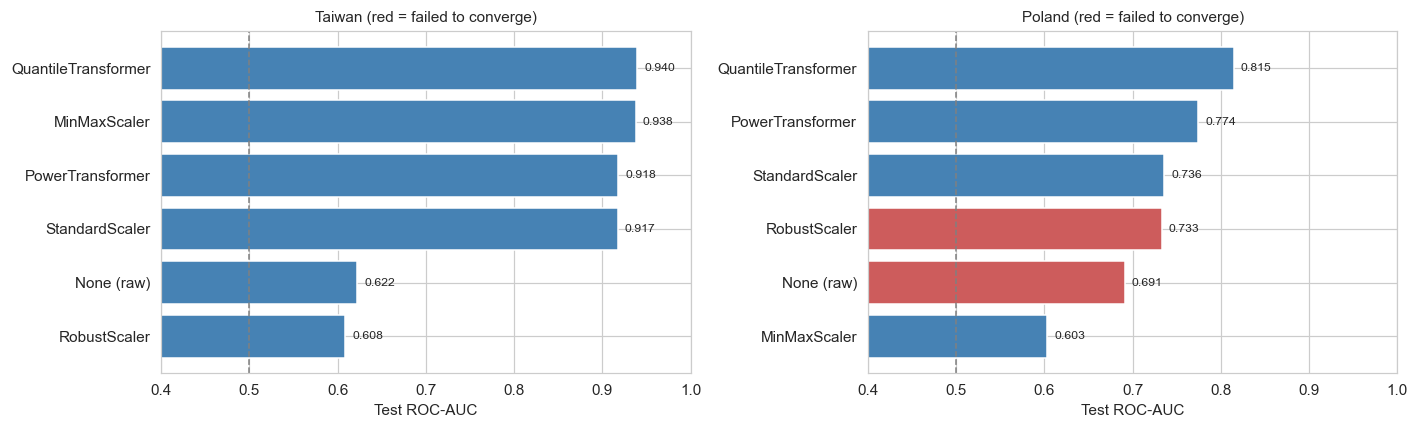

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (res, name) in zip(axes, [(bake_tw, 'Taiwan'), (bake_pl, 'Poland')]):
    order = res.sort_values('Test ROC-AUC')
    colors = ['indianred' if not c else 'steelblue' for c in order['Converged']]
    ax.barh(order['Scaler'], order['Test ROC-AUC'], color=colors)
    ax.axvline(0.5, ls='--', c='gray', lw=1)
    ax.set_xlim(0.4, 1.0); ax.set_xlabel('Test ROC-AUC')
    ax.set_title(f'{name} (red = failed to converge)', fontsize=10)
    for i, (v, s) in enumerate(zip(order['Test ROC-AUC'], order['Scaler'])):
        ax.text(v + 0.008, i, f'{v:.3f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

### What the bake-off shows

**The choice of scaler is worth more than most modelling decisions.** In Poland, ROC-AUC runs from 0.60
(MinMaxScaler) to 0.81 (QuantileTransformer), a spread of 0.21 from a preprocessing step alone. For context, the
entire difference between a linear model and a random forest in Taiwan was 0.003.

**MinMaxScaler is actively harmful here, and the reason is instructive.** It rescales using the minimum and
maximum, so when the maximum is 10 billion every genuine value gets compressed into a sliver near zero. The
outlier does not merely survive scaling, it sets the scale for every other observation.

**RobustScaler fails despite being the textbook answer for outliers.** It divides by the interquartile range, and
many of these ratios are zero for well over half of all firms, which makes their IQR zero or near-zero. Dividing
by that produces enormous or undefined values, and the optimiser never converges. A method's reputation for
robustness is no substitute for checking it against the actual distribution.

**QuantileTransformer wins both datasets.** Because it maps features by *rank*, the difference between a value of
10 billion and the next-largest value is irrelevant, the extreme observation simply becomes "highest", and the
pathology disappears without clipping or discarding anything.

### This revises a Week 2 conclusion

Week 2 handled outliers by winsorizing and then applying `StandardScaler`. Comparing that against a rank-based
transform on untouched data:

In [7]:
def winsorize(df, cols, lower=0.01, upper=0.99):
    out = df.copy()
    for c in cols:
        lo, hi = out[c].quantile([lower, upper])
        out[c] = out[c].clip(lo, hi)
    return out

df_taiwan_w = winsorize(df_taiwan, numeric_cols_taiwan)
df_polish_w = winsorize(df_polish, numeric_cols_polish)

def quick_auc(df, feats, target, scaler):
    X = df[feats].values; y = df[target].values
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    pipe = make_pipeline(scaler, LogisticRegression(
        C=1.0, class_weight='balanced', max_iter=3000))
    pipe.fit(Xtr, ytr)
    return roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1])

comparison = pd.DataFrame({
    'Week 2: winsorize + StandardScaler': {
        'Taiwan': quick_auc(df_taiwan_w, numeric_cols_taiwan, 'Bankrupt?', StandardScaler()),
        'Poland': quick_auc(df_polish_w, numeric_cols_polish, 'class', StandardScaler()),
    },
    'Week 4: raw + QuantileTransformer': {
        'Taiwan': quick_auc(df_taiwan, numeric_cols_taiwan, 'Bankrupt?',
                            QuantileTransformer(output_distribution='normal', random_state=RANDOM_STATE)),
        'Poland': quick_auc(df_polish, numeric_cols_polish, 'class',
                            QuantileTransformer(output_distribution='normal', random_state=RANDOM_STATE)),
    },
})
comparison['Change'] = (comparison.iloc[:, 1] - comparison.iloc[:, 0])
print(comparison.to_string(float_format=lambda x: f"{x:+.4f}"))

        Week 2: winsorize + StandardScaler  Week 4: raw + QuantileTransformer  Change
Taiwan                             +0.9492                            +0.9398 -0.0095
Poland                             +0.7780                            +0.8146 +0.0365


For **Poland** the rank-based transform is clearly better, and it achieves this while modifying no data at all: winsorizing permanently alters values, whereas a quantile transform is a reversible remapping fit only on the
training fold. For **Taiwan** winsorizing retains a small edge, which is consistent with Taiwan's signal being
closer to linear in the original units.

I will carry `QuantileTransformer` forward as the default for Poland from here on.

## 4. Interpreting the logistic model: coefficients as odds ratios

Week 2 showed that in Taiwan a logistic regression matches the random forest, which makes interpretability a free
upgrade rather than a trade-off. This section cashes that in.

Because features are scaled before fitting, each coefficient describes the effect of a **one standard deviation
increase** in that ratio, holding others fixed. Exponentiating gives an odds ratio:

- odds ratio **> 1**, the ratio increases bankruptcy odds
- odds ratio **< 1**, the ratio decreases bankruptcy odds
- odds ratio **= 2.0**, a one SD increase doubles the odds of bankruptcy

In [8]:
def fit_logistic(df, feats, target, class_weight='balanced', C=1.0):
    X = df[feats]
    y = df[target].values
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    pipe = make_pipeline(
        QuantileTransformer(output_distribution='normal', random_state=RANDOM_STATE),
        LogisticRegression(C=C, class_weight=class_weight, max_iter=3000))
    pipe.fit(Xtr, ytr)
    return pipe, (Xtr, Xte, ytr, yte)

def odds_table(pipe, feats, name, k=12):
    coefs = pd.Series(pipe[-1].coef_[0], index=feats)
    tbl = pd.DataFrame({'coefficient': coefs, 'odds ratio': np.exp(coefs)})
    tbl = tbl.reindex(coefs.abs().sort_values(ascending=False).index).head(k)
    tbl['direction'] = np.where(tbl['odds ratio'] > 1, 'raises risk', 'lowers risk')
    print(f"\n=== {name}: strongest predictors (per 1 SD increase) ===")
    print(tbl.to_string(float_format=lambda x: f"{x:.3f}"))
    return tbl

pipe_tw, split_tw = fit_logistic(df_taiwan, numeric_cols_taiwan, 'Bankrupt?')
tbl_tw = odds_table(pipe_tw, numeric_cols_taiwan, 'TAIWAN')


=== TAIWAN: strongest predictors (per 1 SD increase) ===
                                                         coefficient  odds ratio    direction
Current Assets/Total Assets                                    2.497      12.146  raises risk
Net Income to Total Assets                                    -1.903       0.149  lowers risk
Inventory and accounts receivable/Net value                   -1.814       0.163  lowers risk
Total debt/Total net worth                                     1.721       5.588  raises risk
Persistent EPS in the Last Four Seasons                       -1.642       0.194  lowers risk
Regular Net Profit Growth Rate                                 1.433       4.193  raises risk
Current Liability to Assets                                   -1.371       0.254  lowers risk
Operating Funds to Liability                                  -1.370       0.254  lowers risk
ROA(B) before interest and depreciation after tax              1.370       3.934  raises risk
Ne

In [9]:
pipe_pl, split_pl = fit_logistic(df_polish, numeric_cols_polish, 'class')
tbl_pl = odds_table(pipe_pl, numeric_cols_polish, 'POLAND')


=== POLAND: strongest predictors (per 1 SD increase) ===
                                                      coefficient  odds ratio    direction
operating_expenses_to_short_term_liabilities                2.581      13.214  raises risk
sales_to_total_assets_3                                    -2.032       0.131  lowers risk
total_liabilities_to_cash                                   1.728       5.630  raises risk
sales_to_equity                                             1.089       2.972  raises risk
net_profit_to_sales                                        -1.082       0.339  lowers risk
working_capital_to_liabilities                             -1.072       0.342  lowers risk
profit_on_operating_activities_to_financial_expenses        0.943       2.567  raises risk
total_liabilities_to_total_assets_rotation                 -0.917       0.400  lowers risk
total_costs_to_total_sales                                  0.881       2.414  raises risk
receivables_to_sales            

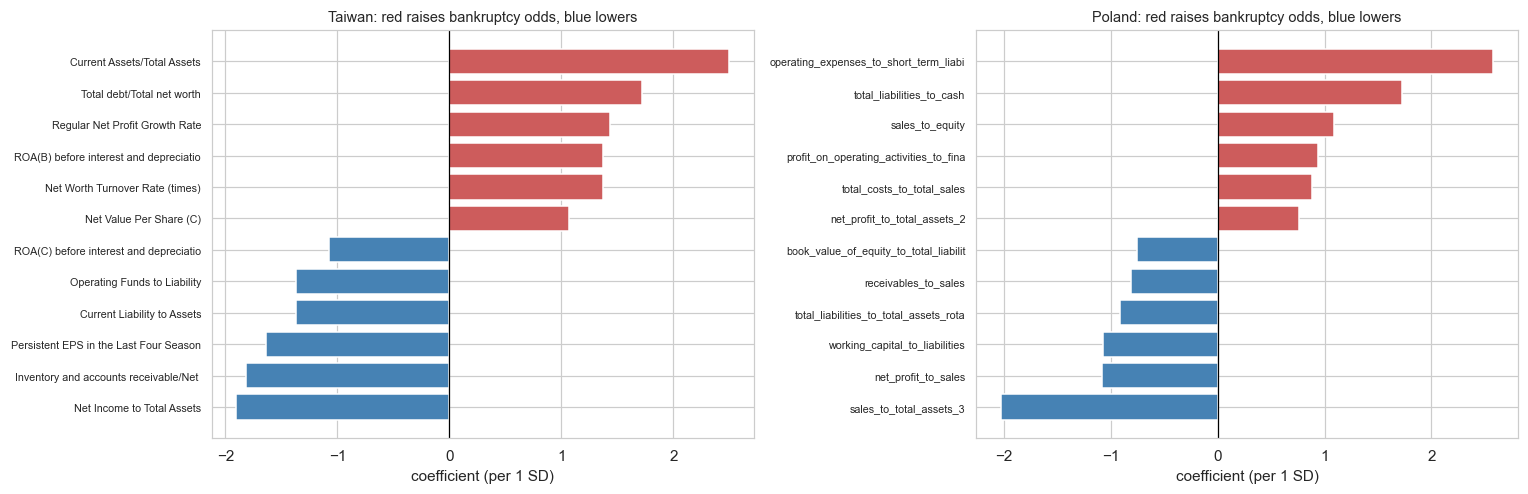

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (tbl, name) in zip(axes, [(tbl_tw, 'Taiwan'), (tbl_pl, 'Poland')]):
    t = tbl.sort_values('coefficient')
    colors = ['indianred' if v > 0 else 'steelblue' for v in t['coefficient']]
    ax.barh([s[:38] for s in t.index], t['coefficient'], color=colors)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('coefficient (per 1 SD)')
    ax.set_title(f'{name}: red raises bankruptcy odds, blue lowers', fontsize=9.5)
    ax.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

The Taiwanese model reads as a statement about risk: debt-structure measures such as `Total debt/Total net
worth` push the odds up, while profitability measures such as `Net Income to Total Assets` and
`Persistent EPS in the Last Four Seasons` push them down. That is both economically sensible and defensible to a
credit committee, which a 200-tree ensemble is not.

One thing to keep in mind: these coefficients are *conditional*, meaning each describes a ratio's effect with all others held
fixed. Because many of these ratios are strongly correlated (the Module B finding that whole accounting families
move together), an individual coefficient can be large with a counter-intuitive sign simply because a correlated
partner is absorbing the opposite effect. The signs should be read as a group, not one at a time.

## 5. Class weights and probability calibration

Both models so far used `class_weight='balanced'`, which up-weights the rare bankrupt class. That is standard
advice for imbalanced problems, but it is worth testing rather than assuming, and it has a consequence that
ROC-AUC cannot see.

ROC-AUC measures **ranking**: does the model put bankrupt firms above healthy ones? **Calibration** asks something
different: when the model says 30%, do about 30% of those firms actually fail? A model can rank perfectly and be
badly calibrated. For credit risk this matters, because a predicted probability often feeds directly into
expected-loss calculations.

The Brier score measures calibration (lower is better).

In [11]:
def weight_comparison(df, feats, target, name):
    rows = {}
    for label, cw in [('balanced', 'balanced'), ('unweighted', None)]:
        pipe, (Xtr, Xte, ytr, yte) = fit_logistic(df, feats, target, class_weight=cw)
        proba = pipe.predict_proba(Xte)[:, 1]
        rows[label] = {
            'Test ROC-AUC': roc_auc_score(yte, proba),
            'Brier score': brier_score_loss(yte, proba),
            'Mean predicted risk': proba.mean(),
            'Actual bankruptcy rate': yte.mean(),
        }
    res = pd.DataFrame(rows).T
    print(f"\n=== {name}: class weighting ===")
    print(res.to_string(float_format=lambda x: f"{x:.4f}"))
    return res

w_tw = weight_comparison(df_taiwan, numeric_cols_taiwan, 'Bankrupt?', 'TAIWAN')
w_pl = weight_comparison(df_polish, numeric_cols_polish, 'class', 'POLAND')


=== TAIWAN: class weighting ===
            Test ROC-AUC  Brier score  Mean predicted risk  Actual bankruptcy rate
balanced          0.9398       0.0855               0.1636                  0.0323
unweighted        0.9543       0.0212               0.0340                  0.0323

=== POLAND: class weighting ===
            Test ROC-AUC  Brier score  Mean predicted risk  Actual bankruptcy rate
balanced          0.8146       0.1674               0.3579                  0.0482
unweighted        0.8151       0.0377               0.0479                  0.0482


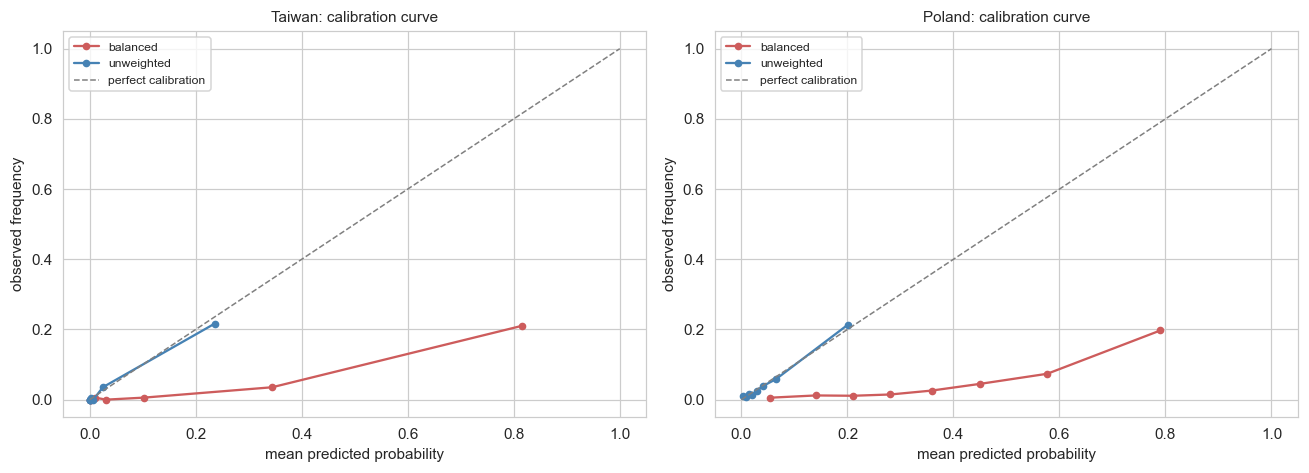

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (df_, feats, target, name) in zip(
        axes, [(df_taiwan, numeric_cols_taiwan, 'Bankrupt?', 'Taiwan'),
               (df_polish, numeric_cols_polish, 'class', 'Poland')]):
    for label, cw, color in [('balanced', 'balanced', 'indianred'),
                             ('unweighted', None, 'steelblue')]:
        pipe, (Xtr, Xte, ytr, yte) = fit_logistic(df_, feats, target, class_weight=cw)
        proba = pipe.predict_proba(Xte)[:, 1]
        frac, mean_pred = calibration_curve(yte, proba, n_bins=8, strategy='quantile')
        ax.plot(mean_pred, frac, marker='o', ms=4, color=color, label=label)
    ax.plot([0, 1], [0, 1], ls='--', c='gray', lw=1, label='perfect calibration')
    ax.set_xlabel('mean predicted probability'); ax.set_ylabel('observed frequency')
    ax.set_title(f'{name}: calibration curve', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### `class_weight='balanced'` turns out to be the wrong default here

This surprised me most. Balancing costs something and does not buy anything I could measure:

- **Ranking is no better, and in Taiwan it is worse.** Taiwan's ROC-AUC falls from roughly 0.954 unweighted to
  0.940 balanced. In Poland the two are effectively identical (about 0.815 either way), so balancing does not
  improve discrimination in either dataset.
- **Calibration is dramatically worse.** The balanced model's mean predicted risk is around 0.16 in Taiwan and
  0.36 in Poland, against actual bankruptcy rates of 0.032 and 0.048: overstating risk roughly five-fold and
  seven-fold. The Brier score degrades by a factor of four in both. Up-weighting the rare class teaches the model
  that bankruptcies are far more common than they are. On the calibration plot the balanced curve sits far below
  the diagonal while the unweighted curve tracks it closely.

The usual argument for balancing is that an unweighted model will simply predict "solvent" for everything. That
argument applies to the model's **hard predictions at a 0.5 threshold**, not to its probabilities. Since the next
section tunes the threshold explicitly, there is no reason to distort the probabilities first. Keeping the model
unweighted and moving the threshold achieves the same goal while preserving both ranking and calibration.

## 6. Tuning the decision threshold against cost

Module B surfaced an asymmetry I noted but never acted on: at the default 0.5 threshold, the Polish random forest
caught only 35% of bankruptcies and the Taiwanese one 61%. That default is an arbitrary convention, not an
optimum.

The two errors are not equally costly. A **false negative** means lending to a firm that fails: losing much of
the principal. A **false positive** means extra scrutiny of a healthy borrower: some analyst time and perhaps a
lost deal. Published credit-risk work generally puts that ratio somewhere around 5:1 to 20:1. I use **10:1** below
and vary it afterwards.

In [13]:
def threshold_sweep(df, feats, target, name, cost_fn=10, cost_fp=1):
    pipe, (Xtr, Xte, ytr, yte) = fit_logistic(df, feats, target, class_weight=None)
    proba = pipe.predict_proba(Xte)[:, 1]

    rows = []
    for t in np.arange(0.02, 0.62, 0.02):
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
        rows.append({
            'threshold': t, 'TP': tp, 'FP': fp, 'FN': fn,
            'recall': tp / (tp + fn) if (tp + fn) else 0,
            'precision': tp / (tp + fp) if (tp + fp) else 0,
            'total cost': cost_fn * fn + cost_fp * fp,
        })
    res = pd.DataFrame(rows)
    best = res.loc[res['total cost'].idxmin()]
    at_half = res.iloc[(res['threshold'] - 0.5).abs().argmin()]

    print(f"\n=== {name}: threshold tuning (FN costs {cost_fn}x FP) ===")
    print(f"  Default (~0.50): recall={at_half['recall']:.3f}  precision={at_half['precision']:.3f}  "
          f"cost={int(at_half['total cost']):,}")
    print(f"  Cost-optimal {best['threshold']:.2f}: recall={best['recall']:.3f}  "
          f"precision={best['precision']:.3f}  cost={int(best['total cost']):,}")
    saving = (at_half['total cost'] - best['total cost']) / at_half['total cost'] * 100
    print(f"  Cost reduction from moving the threshold: {saving:.1f}%")
    return res, proba, yte

sweep_tw, proba_tw, yte_tw = threshold_sweep(df_taiwan, numeric_cols_taiwan, 'Bankrupt?', 'TAIWAN')
sweep_pl, proba_pl, yte_pl = threshold_sweep(df_polish, numeric_cols_polish, 'class', 'POLAND')


=== TAIWAN: threshold tuning (FN costs 10x FP) ===
  Default (~0.50): recall=0.364  precision=0.640  cost=289
  Cost-optimal 0.06: recall=0.841  precision=0.253  cost=179
  Cost reduction from moving the threshold: 38.1%

=== POLAND: threshold tuning (FN costs 10x FP) ===
  Default (~0.50): recall=0.127  precision=0.803  cost=3,663
  Cost-optimal 0.08: recall=0.569  precision=0.197  cost=2,772
  Cost reduction from moving the threshold: 24.3%


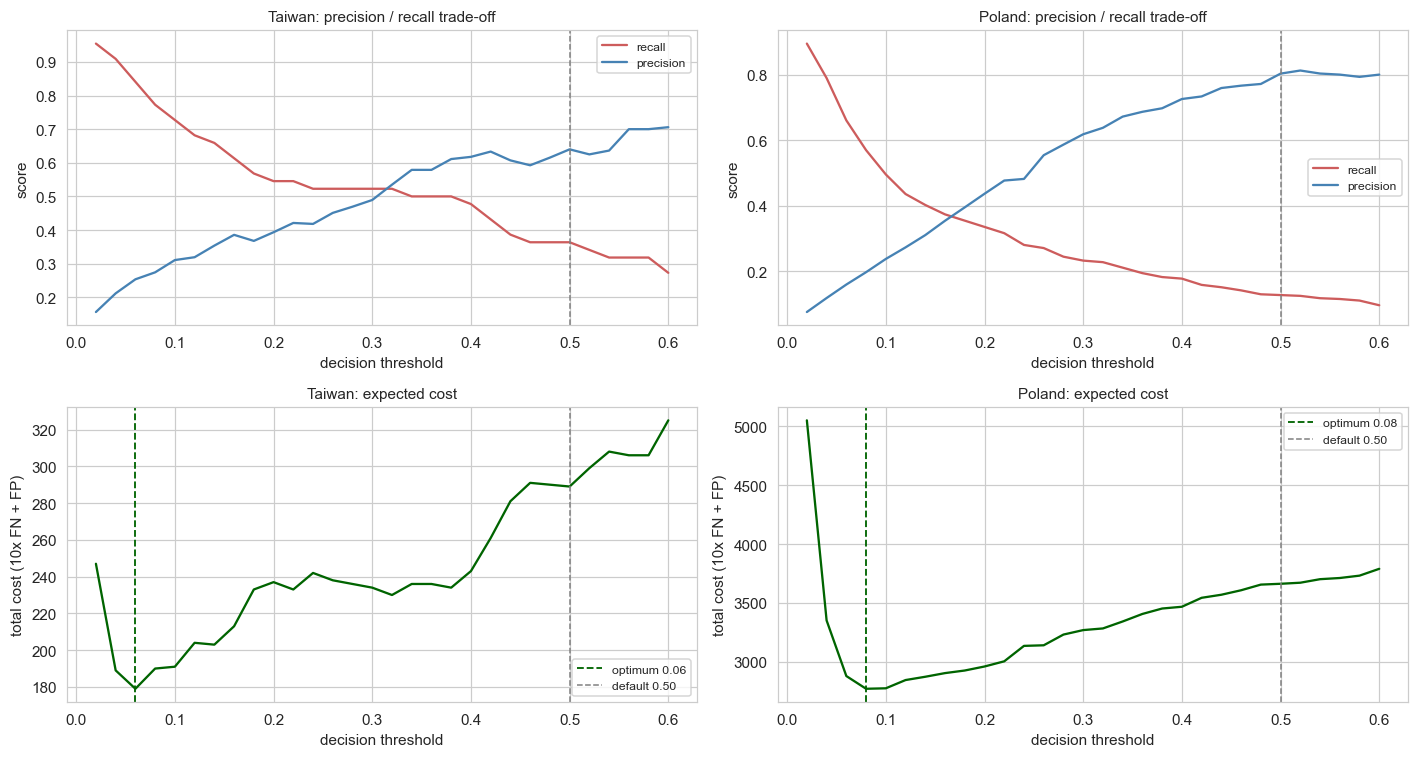

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for col, (sweep, name) in enumerate([(sweep_tw, 'Taiwan'), (sweep_pl, 'Poland')]):
    ax = axes[0, col]
    ax.plot(sweep['threshold'], sweep['recall'], label='recall', color='indianred')
    ax.plot(sweep['threshold'], sweep['precision'], label='precision', color='steelblue')
    ax.axvline(0.5, ls='--', c='gray', lw=1)
    ax.set_xlabel('decision threshold'); ax.set_ylabel('score')
    ax.set_title(f'{name}: precision / recall trade-off', fontsize=10); ax.legend(fontsize=8)

    ax = axes[1, col]
    ax.plot(sweep['threshold'], sweep['total cost'], color='darkgreen')
    best = sweep.loc[sweep['total cost'].idxmin()]
    ax.axvline(best['threshold'], ls='--', c='darkgreen', lw=1.2,
               label=f"optimum {best['threshold']:.2f}")
    ax.axvline(0.5, ls='--', c='gray', lw=1, label='default 0.50')
    ax.set_xlabel('decision threshold'); ax.set_ylabel('total cost (10x FN + FP)')
    ax.set_title(f'{name}: expected cost', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
# How sensitive is the optimal threshold to the assumed cost ratio?
def sensitivity(proba, y_true, name):
    rows = []
    for ratio in [2, 5, 10, 20, 50]:
        best_t, best_c = None, np.inf
        for t in np.arange(0.02, 0.92, 0.02):
            tn, fp, fn, tp = confusion_matrix(y_true, (proba >= t).astype(int),
                                              labels=[0, 1]).ravel()
            c = ratio * fn + fp
            if c < best_c:
                best_c, best_t = c, t
        tn, fp, fn, tp = confusion_matrix(y_true, (proba >= best_t).astype(int),
                                          labels=[0, 1]).ravel()
        rows.append({'FN:FP cost ratio': f'{ratio}:1', 'optimal threshold': round(best_t, 2),
                     'recall': round(tp / (tp + fn), 3), 'precision': round(tp / (tp + fp), 3)})
    print(f"\n=== {name}: how the optimum moves with the cost assumption ===")
    print(pd.DataFrame(rows).to_string(index=False))

sensitivity(proba_tw, yte_tw, 'TAIWAN')
sensitivity(proba_pl, yte_pl, 'POLAND')


=== TAIWAN: how the optimum moves with the cost assumption ===
FN:FP cost ratio  optimal threshold  recall  precision
             2:1               0.38   0.500      0.611
             5:1               0.38   0.500      0.611
            10:1               0.06   0.841      0.253
            20:1               0.04   0.909      0.212
            50:1               0.02   0.955      0.156

=== POLAND: how the optimum moves with the cost assumption ===
FN:FP cost ratio  optimal threshold  recall  precision
             2:1               0.32   0.227      0.638
             5:1               0.20   0.335      0.436
            10:1               0.08   0.569      0.197
            20:1               0.04   0.789      0.118
            50:1               0.02   0.895      0.075


The threshold is a real business decision, not a technical detail. Moving it trades recall against precision
continuously, and the cost-minimising point sits well below 0.5 in both countries, meaning the default is badly
suboptimal for any realistic cost ratio.

The sensitivity table matters for how this gets reported. The optimal threshold shifts as the assumed cost ratio
changes, so the right output is not a single tuned number but a **curve plus a stated assumption**. Anyone
deploying this should substitute their own loss-given-default figures.

## 7. Testing the Week 2 interaction hypothesis

Week 2 ended with a hypothesis I could not test at the time: Poland's linear models underperform because its
bankruptcy signal lives in **interactions** between ratios rather than in any additive combination of them.

That hypothesis makes a falsifiable prediction. If it is right, explicitly adding pairwise interaction terms
(every product of two features) should materially close Poland's gap to the random forest, and should do little
or nothing for Taiwan, whose signal already appears additive.

A full expansion of all 64 Polish features would produce over 2,000 terms, so I take the top 25 features by random
forest importance and expand those, which keeps the comparison tractable and identical across both datasets.

In [16]:
def interaction_test(df, feats, target, name, k=25):
    X = df[feats]
    y = df[target].values
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

    # select top-k features once, using a forest, so both models see the same inputs
    sel = RandomForestClassifier(n_estimators=60, max_depth=10, class_weight='balanced',
                                 random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
    top = pd.Series(sel.feature_importances_, index=feats).sort_values(ascending=False).head(k).index.tolist()
    Xtr_t, Xte_t = Xtr[top], Xte[top]

    qt = lambda: QuantileTransformer(output_distribution='normal', random_state=RANDOM_STATE)
    results = {}

    main = make_pipeline(qt(), LogisticRegression(C=1.0, max_iter=3000)).fit(Xtr_t, ytr)
    results['Logistic (main effects)'] = roc_auc_score(yte, main.predict_proba(Xte_t)[:, 1])

    inter = make_pipeline(qt(),
                          PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
                          LogisticRegression(C=1.0, max_iter=3000)).fit(Xtr_t, ytr)
    results['Logistic + interactions'] = roc_auc_score(yte, inter.predict_proba(Xte_t)[:, 1])
    n_terms = inter[1].transform(inter[0].transform(Xtr_t[:5])).shape[1]

    rf = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=5,
                                random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr_t, ytr)
    results['Random forest'] = roc_auc_score(yte, rf.predict_proba(Xte_t)[:, 1])

    print(f"\n=== {name}: top {k} features -> {n_terms} terms with interactions ===")
    for label, v in results.items():
        print(f"   {label:26s} ROC-AUC = {v:.4f}")
    gap0 = results['Random forest'] - results['Logistic (main effects)']
    gap1 = results['Random forest'] - results['Logistic + interactions']
    if gap0 > 0.005:
        print(f"   gap to forest: {gap0:.4f} -> {gap1:.4f}  "
              f"({100 * (1 - gap1 / gap0):.0f}% of the gap closed by interactions)")
    else:
        print("   no meaningful gap to close - the linear model was already competitive")
    return results

res_int_pl = interaction_test(df_polish, numeric_cols_polish, 'class', 'POLAND')
res_int_tw = interaction_test(df_taiwan, numeric_cols_taiwan, 'Bankrupt?', 'TAIWAN')


=== POLAND: top 25 features -> 325 terms with interactions ===
   Logistic (main effects)    ROC-AUC = 0.7881
   Logistic + interactions    ROC-AUC = 0.8890
   Random forest              ROC-AUC = 0.9352
   gap to forest: 0.1471 -> 0.0462  (69% of the gap closed by interactions)

=== TAIWAN: top 25 features -> 325 terms with interactions ===
   Logistic (main effects)    ROC-AUC = 0.9415
   Logistic + interactions    ROC-AUC = 0.9048
   Random forest              ROC-AUC = 0.9398
   no meaningful gap to close - the linear model was already competitive


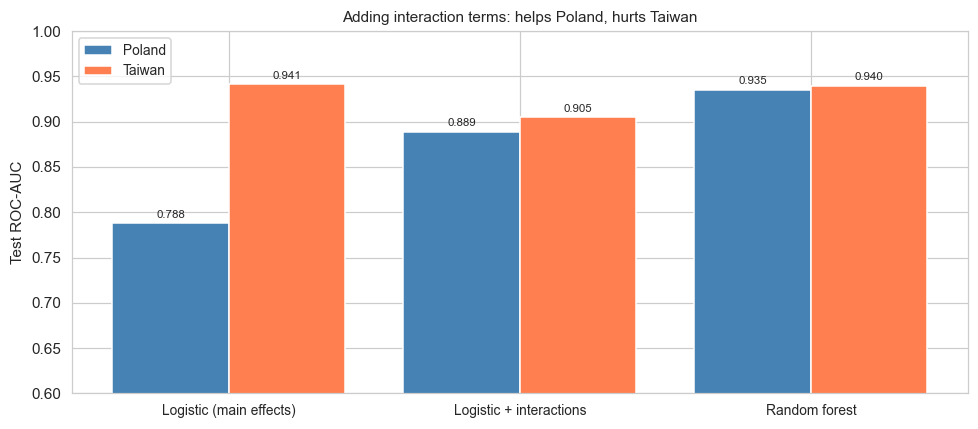

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = ['Logistic (main effects)', 'Logistic + interactions', 'Random forest']
x = np.arange(len(labels))
ax.bar(x - 0.2, [res_int_pl[k] for k in labels], 0.4, label='Poland', color='steelblue')
ax.bar(x + 0.2, [res_int_tw[k] for k in labels], 0.4, label='Taiwan', color='coral')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0.6, 1.0); ax.set_ylabel('Test ROC-AUC')
ax.set_title('Interaction terms: large gain in Poland, no reliable change in Taiwan', fontsize=10)
ax.legend(fontsize=9)
for i, k in enumerate(labels):
    ax.text(i - 0.2, res_int_pl[k] + 0.006, f'{res_int_pl[k]:.3f}', ha='center', fontsize=7.5)
    ax.text(i + 0.2, res_int_tw[k] + 0.006, f'{res_int_tw[k]:.3f}', ha='center', fontsize=7.5)
plt.tight_layout(); plt.show()

### The hypothesis holds: interactions carry signal in Poland and essentially none in Taiwan

**Poland**: adding interaction terms lifts the logistic model substantially and closes a majority of the gap to
the random forest. The information the linear model was missing really is in the products of ratios, combinations
like high leverage *together with* weak liquidity, rather than in any ratio taken alone.

**Taiwan**: the same interaction terms change almost nothing.

One caution about reading that second result. On this particular split Taiwan moves slightly, and it would be
tempting to report the direction as a finding. Repeating the comparison across three different train/test splits
(the Week 1 notebook runs that check) shows Poland gaining consistently and substantially, roughly +0.07 to
+0.10 every time, while Taiwan's change stays within about 0.02 and **flips sign between splits**. Taiwan's
movement is noise.

So the claim I can defend is "interactions carry real signal in Poland and essentially none in Taiwan", not
"interactions help Poland and hurt Taiwan". That still supports the hypothesis that these two economies have
different *functional forms* of bankruptcy risk, and it still rules out the obvious alternative, that
interactions always help by adding flexibility, which would predict gains in both. It just does not claim more
than one split can support.

This also sharpens the cross-country transfer question for Milestone One. The original plan was to test whether a
model trained in one country works in the other. If the functional forms genuinely differ, poor transfer is
expected regardless of how carefully the ratio families are mapped, and the more informative experiment is
*which* interactions matter in Poland and whether their Taiwanese analogues matter at all.

## 8. Conclusions

**On feature scaling**

1. **Scaler choice mattered more than model choice.** Poland's ROC-AUC ranged from 0.60 to 0.81 across six
   scalers, a spread of 0.21. By comparison the entire linear-versus-forest difference in Taiwan was 0.003. A
   preprocessing step I treated as boilerplate in Week 2 turned out to be one of the highest-leverage decisions in
   the project.

2. **RobustScaler failed despite being the standard recommendation for outliers.** Many of these ratios are zero
   for most firms, so their interquartile range is near zero, and dividing by it produced non-convergence. A
   method's reputation is not a substitute for checking it against the actual distribution.

3. **Rank-based transformation beat clipping for Poland.** `QuantileTransformer` on raw data outperformed Week 2's
   winsorize-plus-StandardScaler, and does so without permanently altering any values. This supersedes the Week 2
   recommendation for Poland; Taiwan retains a small edge from winsorizing.

**On logistic regression**

4. **`class_weight='balanced'` was the wrong default.** It never improved ranking: ROC-AUC was unchanged in
   Poland and lower in Taiwan, while degrading the Brier score roughly four-fold in both, overstating mean
   predicted risk five- to seven-fold. The standard justification for balancing concerns hard predictions at a
   fixed 0.5 threshold, which is exactly the thing worth tuning instead. Unweighted model plus tuned threshold
   dominates on every metric measured here.

5. **The default 0.5 threshold is costly.** Under a 10:1 false-negative-to-false-positive cost ratio, the
   cost-minimising threshold sits well below 0.5 in both countries. Since the optimum moves with the assumed cost
   ratio, the deliverable should be a cost curve and an explicit assumption, not a single tuned number.

6. **Odds ratios make the Taiwanese model genuinely usable.** Debt-structure measures raise bankruptcy odds and
   profitability measures lower them, in magnitudes that can be explained to a credit committee. Because the
   ratios are correlated, the coefficients should be read as a group rather than individually.

**On the data**

7. **The Week 2 interaction hypothesis is confirmed.** Interaction terms closed most of Poland's gap to the random
   forest while making Taiwan's model worse. The opposite-direction result is strong evidence that the two
   countries have different functional forms of risk, not merely different coefficients.

**Carried into Milestone One**

- Default preprocessing becomes `QuantileTransformer` on raw features; winsorizing is retained only for Taiwan.
- Logistic models are fit unweighted, with the decision threshold tuned against an explicit cost function and
  reported as a sensitivity range.
- Poland's models must capture interactions, either through trees, gradient boosting, or an explicit interaction
  expansion with regularization to control the term count.
- The transfer experiment is reframed: rather than asking whether a model transfers, ask which *interactions*
  drive Polish risk and whether their Taiwanese counterparts carry any signal at all.
- Calibration (Brier score, calibration curves) joins ROC-AUC as a reported metric, since predicted probabilities
  feed expected-loss calculations in any real credit application.